In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

In [2]:
loader = HFDatasetLoader(
    dataset_name="Vishaltiwari2019/Car-Price-Prediction",
    split="train",
    filename="datos/car_price_ml_regressionlineal.csv",
)

In [3]:
df = loader.load()
df.head(2)

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
0,Honda,Model B,2015,3.9,74176,Petrol,Manual,30246.207931
1,Ford,Model C,2014,1.7,94799,Electric,Automatic,22785.747684


## Regresion lineal simple

In [4]:
df["Mileage"].head()

0     74176
1     94799
2     98385
3     88919
4    138482
Name: Mileage, dtype: int64

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

X, y = df[["Mileage"]], df["Price"] # preparar datos
modelo = LinearRegression() #inicializar modelo

X_train, X_test, y_train, y_test = train_test_split( #dividir_datos
    X, y, test_size=0.2, random_state=42
)

modelo.fit(X_train, y_train)# entrenamiento
predicciones = modelo.predict(X_test) # prediccion
w = modelo.coef_[0]
b = modelo.intercept_

print(f"MAE: {mean_absolute_error(y_test, predicciones):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predicciones)):.2f}")
print(f"R2: {r2_score(y_test, predicciones):.2f}")
print(f"w: {w:.2f}")
print(f"b: {b:.2f}")

MAE: 3729.56
RMSE: 4458.21
R2: 0.27
w: -0.05
b: 29979.97


In [6]:
%pip install --upgrade matplotlib

Note: you may need to restart the kernel to use updated packages.


[graficos](https://matplotlib.org/cheatsheets/_images/cheatsheets-1.png)

In [7]:
%matplotlib inline

In [8]:
import sys
import matplotlib

print(sys.executable)
print(matplotlib.__version__)

/workspaces/ML_2026Q4/.venv/bin/python
3.11.2


In [9]:
import matplotlib.pyplot as plt
from IPython.display import display

x_test = X_test["Mileage"].to_numpy()
y_test_array = y_test.to_numpy()
orden = x_test.argsort()



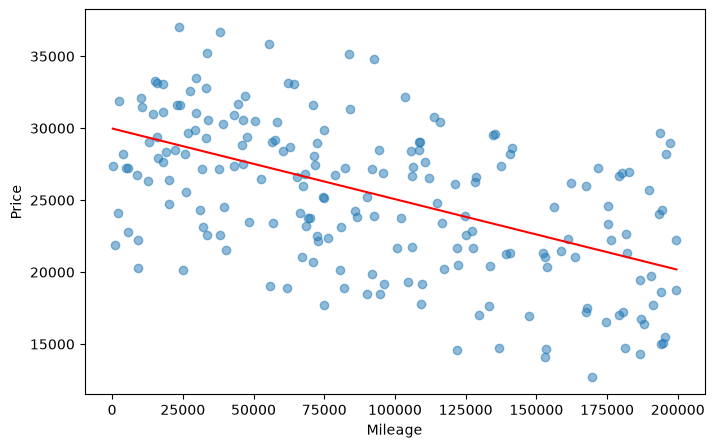

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x_test,
    y_test_array,
    alpha=0.5,
)

ax.plot(
    x_test[orden],
    predicciones[orden],
    color="red",
)

ax.set_xlabel("Mileage")
ax.set_ylabel("Price")

display(fig)
plt.close(fig)

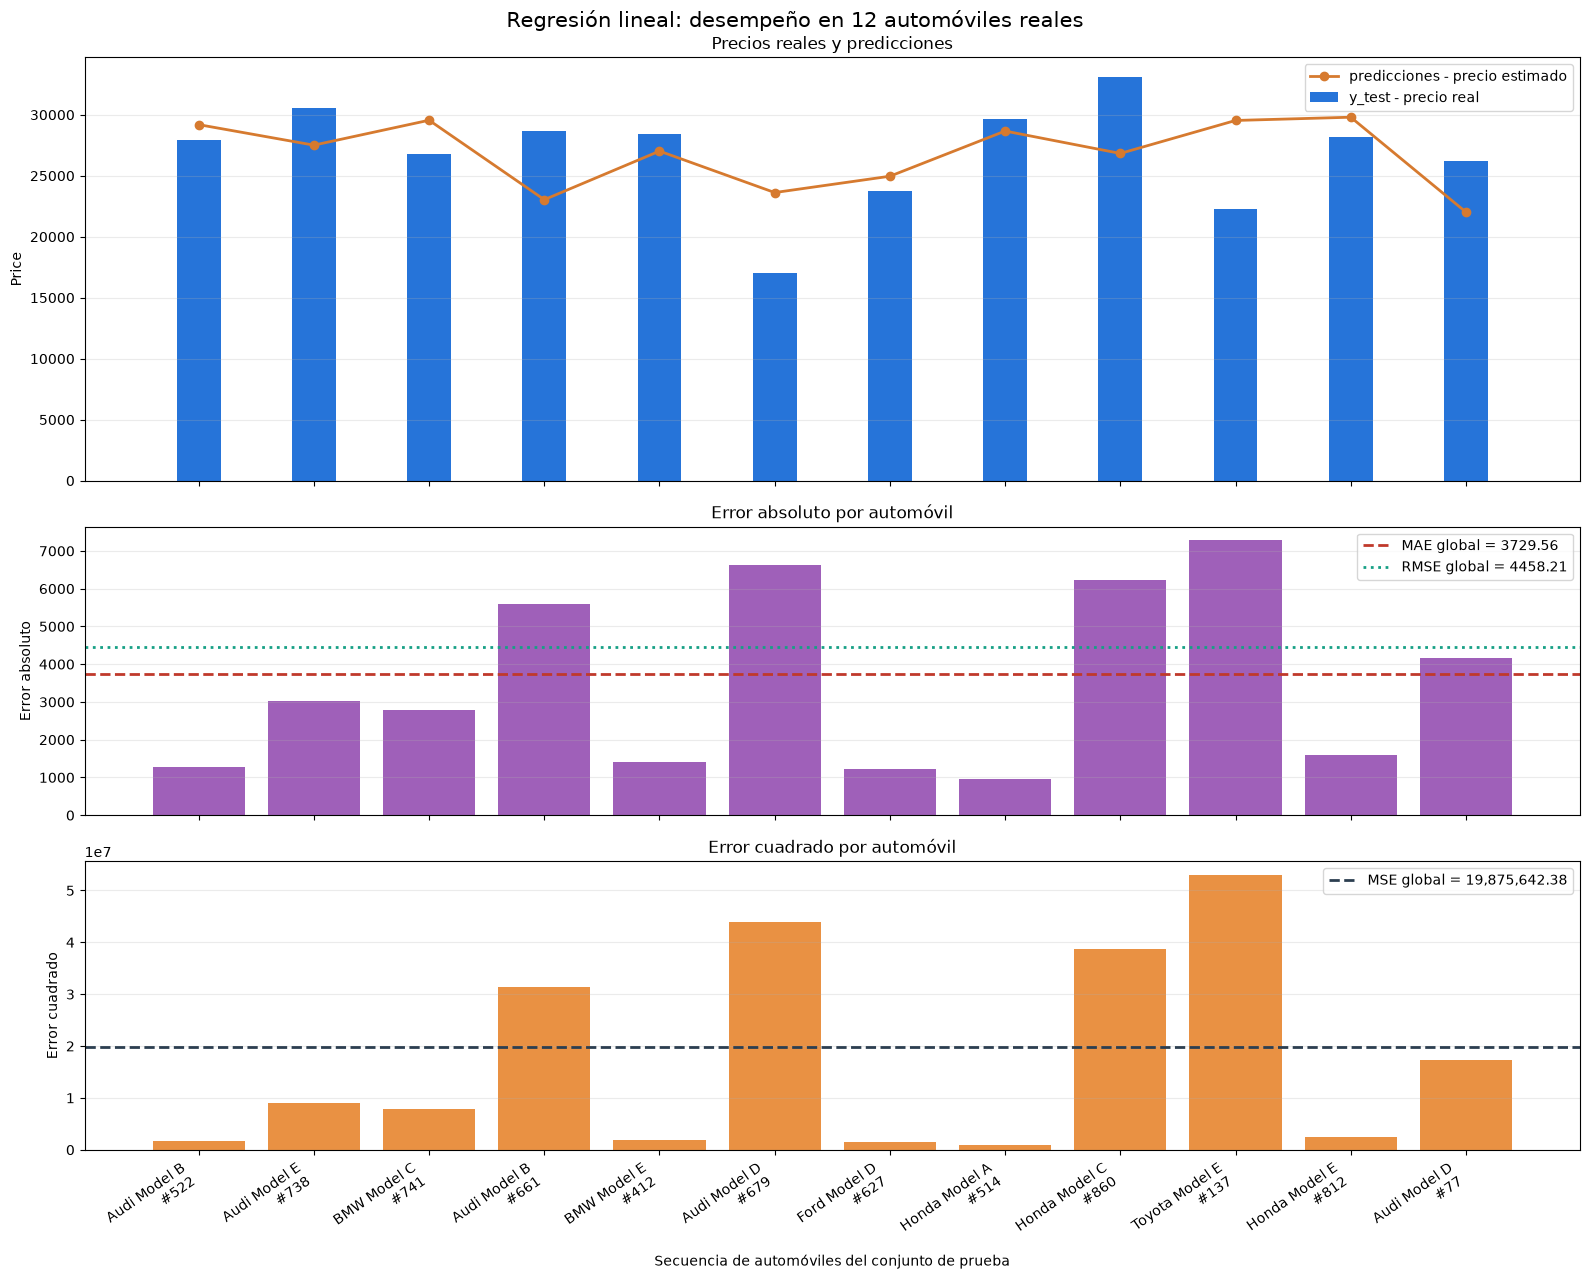

Automóviles mostrados: 12 de 200
Métricas globales - MAE: 3729.56; RMSE: 4458.21; MSE: 19,875,642.38
Métricas de la selección - MAE: 3517.35; RMSE: 4184.13; MSE: 17,506,903.64


In [11]:
# Comparación combinada para una selección legible de automóviles reales
indices_test = y_test.index.to_numpy()
y_test_array = y_test.to_numpy()
predicciones_array = np.asarray(predicciones)

# Se muestran 12 automóviles, manteniendo el orden del conjunto de prueba.
seleccion = np.arange(min(12, len(y_test_array)))
y_real = y_test_array[seleccion]
y_predicha = predicciones_array[seleccion]
errores = y_real - y_predicha
error_absoluto = np.abs(errores)
error_cuadrado = errores ** 2
etiquetas = [
    f"{df.loc[indices_test[i], 'Make']} {df.loc[indices_test[i], 'Model']}\n#{indices_test[i] + 1}"
    for i in seleccion
]

mae_global = mean_absolute_error(y_test_array, predicciones_array)
rmse_global = np.sqrt(mean_squared_error(y_test_array, predicciones_array))
mse_global = mean_squared_error(y_test_array, predicciones_array)
posiciones = np.arange(len(seleccion))
ancho = 0.38

fig, (ax_precios, ax_absoluto, ax_cuadrado) = plt.subplots(
    3, 1, figsize=(16, 13), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.5, 1.5]},
)

# Arriba: precio real en barras y predicción como línea con puntos.
ax_precios.bar(posiciones, y_real, ancho, label="y_test - precio real", color="#2674d9")
ax_precios.plot(posiciones, y_predicha, color="#d67a2f", marker="o", linewidth=2,
                label="predicciones - precio estimado")
ax_precios.set_ylabel("Price")
ax_precios.set_title("Precios reales y predicciones")
ax_precios.legend()
ax_precios.grid(axis="y", alpha=0.25)

# En medio: errores absolutos y referencias globales del modelo.
ax_absoluto.bar(posiciones, error_absoluto, color="#8e44ad", alpha=0.85)
ax_absoluto.axhline(mae_global, color="#c0392b", linestyle="--", linewidth=2,
                    label=f"MAE global = {mae_global:.2f}")
ax_absoluto.axhline(rmse_global, color="#16a085", linestyle=":", linewidth=2,
                    label=f"RMSE global = {rmse_global:.2f}")
ax_absoluto.set_ylabel("Error absoluto")
ax_absoluto.set_title("Error absoluto por automóvil")
ax_absoluto.legend()
ax_absoluto.grid(axis="y", alpha=0.25)

# Abajo: errores cuadrados y referencia global del MSE.
ax_cuadrado.bar(posiciones, error_cuadrado, color="#e67e22", alpha=0.85)
ax_cuadrado.axhline(mse_global, color="#2c3e50", linestyle="--", linewidth=2,
                    label=f"MSE global = {mse_global:,.2f}")
ax_cuadrado.set_ylabel("Error cuadrado")
ax_cuadrado.set_title("Error cuadrado por automóvil")
ax_cuadrado.legend()
ax_cuadrado.grid(axis="y", alpha=0.25)

ax_cuadrado.set_xticks(posiciones)
ax_cuadrado.set_xticklabels(etiquetas, rotation=35, ha="right")
ax_cuadrado.set_xlabel("Secuencia de automóviles del conjunto de prueba")
fig.suptitle("Regresión lineal: desempeño en 12 automóviles reales", fontsize=15)
fig.tight_layout()
display(fig)
plt.close(fig)

print(f"Automóviles mostrados: {len(seleccion)} de {len(y_test_array)}")
print(f"Métricas globales - MAE: {mae_global:.2f}; RMSE: {rmse_global:.2f}; MSE: {mse_global:,.2f}")
print(f"Métricas de la selección - MAE: {error_absoluto.mean():.2f}; RMSE: {np.sqrt(error_cuadrado.mean()):.2f}; MSE: {error_cuadrado.mean():,.2f}")


Filas: 1000 | duplicados exactos: 0
Valores faltantes por columna:
Sin valores faltantes


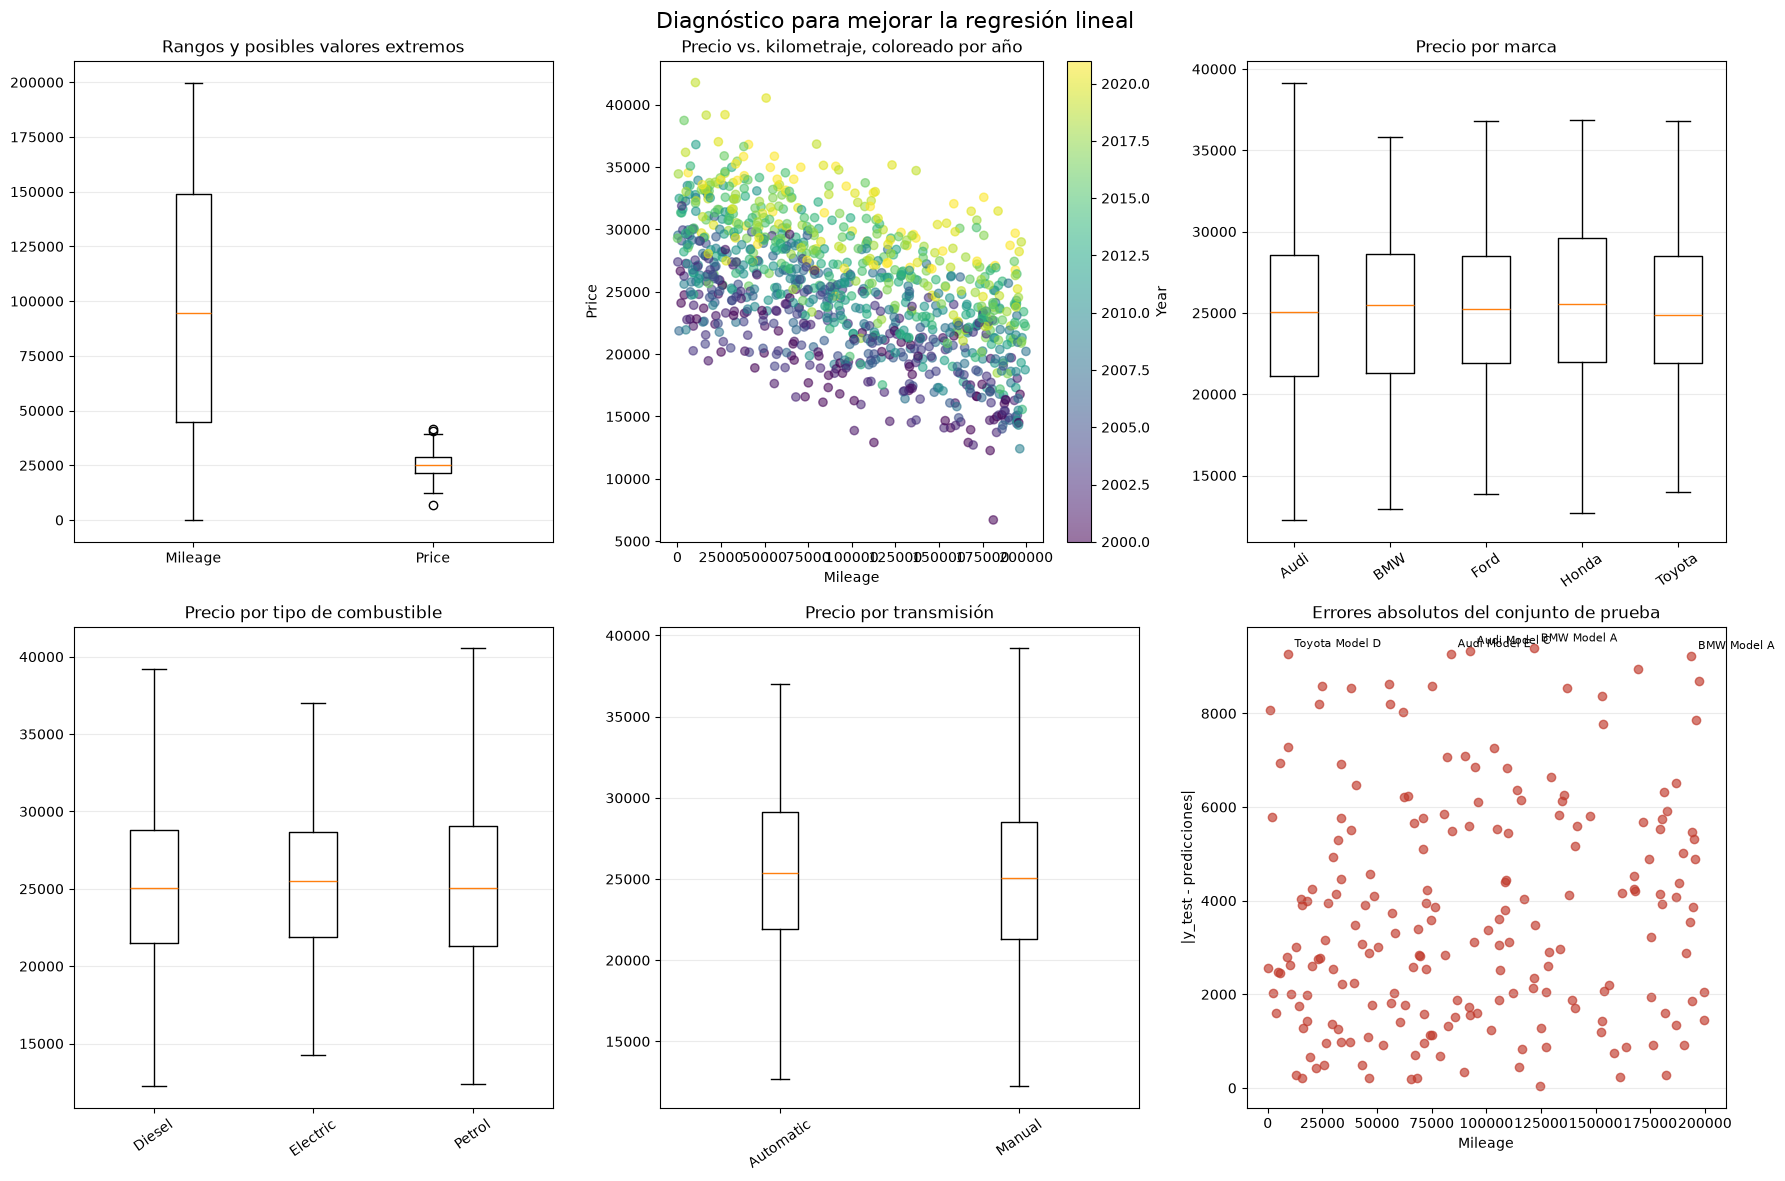


Mayores errores absolutos del conjunto de prueba:
       Make    Model  Year  Mileage        y_test  predicciones  error_absoluto
617     BMW  Model A  2001   121764  14615.388153  24003.347595     9387.959443
753    Audi  Model C  2019    92510  34776.253205  25439.239908     9337.013298
429  Toyota  Model D  2003     9032  20268.007565  29536.642603     9268.635038
604    Audi  Model E  2020    83721  35137.562945  25870.635872     9266.927073
749     BMW  Model A  2021   193708  29698.544696  20472.075409     9226.469287

Cobertura de categorías:
Make: 5 categorías | mínimo por categoría: 178
Model: 5 categorías | mínimo por categoría: 184
Fuel Type: 3 categorías | mínimo por categoría: 325
Transmission: 2 categorías | mínimo por categoría: 489


In [12]:
# Diagnóstico visual para decidir cómo mejorar el modelo
columnas_requeridas = [
    "Make", "Model", "Year", "Engine Size", "Mileage",
    "Fuel Type", "Transmission", "Price",
]
columnas_disponibles = [columna for columna in columnas_requeridas if columna in df.columns]
filas_duplicadas = int(df.duplicated().sum())
valores_faltantes = df[columnas_disponibles].isna().sum()
print(f"Filas: {len(df)} | duplicados exactos: {filas_duplicadas}")
print("Valores faltantes por columna:")
print(valores_faltantes[valores_faltantes > 0] if valores_faltantes.any() else "Sin valores faltantes")

# Preparar la información del conjunto de prueba para investigar errores.
indices_test = y_test.index.to_numpy()
prueba = df.loc[indices_test, columnas_disponibles].copy(deep=True)
prueba["y_test"] = y_test.to_numpy()
prueba["predicciones"] = np.asarray(predicciones)
prueba.loc[:, "error_absoluto"] = np.abs(prueba["y_test"] - prueba["predicciones"])
prueba.loc[:, "error_cuadrado"] = (prueba["y_test"] - prueba["predicciones"]) ** 2

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Revisar rangos y posibles valores extremos.
axes[0, 0].boxplot(
    [df["Mileage"].dropna(), df["Price"].dropna()],
    tick_labels=["Mileage", "Price"],
    showfliers=True,
)
axes[0, 0].set_title("Rangos y posibles valores extremos")
axes[0, 0].grid(axis="y", alpha=0.25)

# 2. Comprobar si el año aporta una relación visible con el precio.
scatter = axes[0, 1].scatter(
    df["Mileage"], df["Price"], c=df["Year"], cmap="viridis", alpha=0.55
)
axes[0, 1].set_title("Precio vs. kilometraje, coloreado por año")
axes[0, 1].set_xlabel("Mileage")
axes[0, 1].set_ylabel("Price")
fig.colorbar(scatter, ax=axes[0, 1], label="Year")

# 3. Comparar precios entre marcas.
marcas = sorted(df["Make"].dropna().unique())
axes[0, 2].boxplot(
    [df.loc[df["Make"] == marca, "Price"].dropna() for marca in marcas],
    tick_labels=marcas,
    showfliers=False,
)
axes[0, 2].set_title("Precio por marca")
axes[0, 2].tick_params(axis="x", rotation=35)
axes[0, 2].grid(axis="y", alpha=0.25)

# 4. Comparar precios entre tipos de combustible.
combustibles = sorted(df["Fuel Type"].dropna().unique())
axes[1, 0].boxplot(
    [df.loc[df["Fuel Type"] == tipo, "Price"].dropna() for tipo in combustibles],
    tick_labels=combustibles,
    showfliers=False,
)
axes[1, 0].set_title("Precio por tipo de combustible")
axes[1, 0].tick_params(axis="x", rotation=35)
axes[1, 0].grid(axis="y", alpha=0.25)

# 5. Comparar precios entre transmisiones.
transmisiones = sorted(df["Transmission"].dropna().unique())
axes[1, 1].boxplot(
    [df.loc[df["Transmission"] == tipo, "Price"].dropna() for tipo in transmisiones],
    tick_labels=transmisiones,
    showfliers=False,
)
axes[1, 1].set_title("Precio por transmisión")
axes[1, 1].tick_params(axis="x", rotation=35)
axes[1, 1].grid(axis="y", alpha=0.25)

# 6. Localizar los automóviles que el modelo describe peor.
prueba_ordenada = prueba.sort_values("error_absoluto", ascending=False)
axes[1, 2].scatter(
    prueba["Mileage"], prueba["error_absoluto"], color="#c0392b", alpha=0.65
)
axes[1, 2].set_title("Errores absolutos del conjunto de prueba")
axes[1, 2].set_xlabel("Mileage")
axes[1, 2].set_ylabel("|y_test - predicciones|")
axes[1, 2].grid(axis="y", alpha=0.25)
for indice, fila in prueba_ordenada.head(5).iterrows():
    axes[1, 2].annotate(
        f"{df.loc[indice, 'Make']} {df.loc[indice, 'Model']}",
        (fila["Mileage"], fila["error_absoluto"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

fig.suptitle("Diagnóstico para mejorar la regresión lineal", fontsize=16)
fig.tight_layout()
display(fig)
plt.close(fig)

print("\nMayores errores absolutos del conjunto de prueba:")
print(
    prueba_ordenada[["Make", "Model", "Year", "Mileage", "y_test", "predicciones", "error_absoluto"]]
    .head(5)
    .to_string()
)
print("\nCobertura de categorías:")
for columna in ["Make", "Model", "Fuel Type", "Transmission"]:
    print(f"{columna}: {df[columna].nunique()} categorías | mínimo por categoría: {df[columna].value_counts().min()}")

#### Preparar Datos

X, y = regresion.preparar_datos(df) # 
    def preparar_datos(
        self,
        df: pd.DataFrame,
        X_columnas: str | list[str] | tuple[str, ...],
        y_objetivo: str,
    ) -> tuple[pd.DataFrame, pd.Series]:

X_train, X_test, y_train, y_test = regresion.dividir_datos(X, y)
    def dividir_datos(
        X: pd.DataFrame,
        y: pd.Series,
        test_size: float = 0.2,
        random_state: int = 42,
    ) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
modelo = regresion.entrenar(X_train, y_train)
    def entrenar(
        self,
        X_train: pd.DataFrame,
        y_train: pd.Series,
        directorio_entrenamiento: str | Path = "entrenamiento",
    ) -> dict[str, Any]:

predicciones = regresion.predecir(modelo, X_test)
    def predecir(
        self,
        ruta_modelo: str | Path,
        X_test: float | int | list[float] | tuple[float, ...] | pd.DataFrame,
    ) -> np.ndarray:

parametros = regresion.obtener_parametros(modelo)
    def obtener_parametros(
        self, ruta_modelo: str | Path
    ) -> dict[str, float | list[float]]:

metricas = regresion.evaluar(y_test, predicciones)
    def evaluar(
        self,
        ruta_modelo: str | Path,
        X_test: float | int | list[float] | tuple[float, ...] | pd.DataFrame,
        y_test: pd.Series,
    ) -> dict[str, float]:

In [13]:
from clases_po import RegresionLineal

In [15]:
regresion_simple = RegresionLineal(feature_column = "Mileage",target_column = "Price",test_size = 0.2, random_state =42)

In [17]:
X2, y2 = regresion_simple.preparar_datos(df=df,X_columnas=["Year","Mileage"],y_objetivo="Price")

[preparar_datos] X=['Year', 'Mileage'], y='Price'; 1000 filas válidas; 0 filas eliminadas; X=(1000, 2), y=(1000,).


In [18]:
X2_train, X2_test, y2_train, y2_test =regresion_simple.dividir_datos(X= X2,y=y2,test_size = 0.2,random_state = 42)

[dividir_datos] test_size=0.20; random_state=42; entrenamiento=800 filas (800, 2); prueba=200 filas (200, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.


In [19]:
datos_entrenamiento = regresion_simple.entrenar(X_train=X2_train,y_train=y2_train,directorio_entrenamiento = "entrenamiento")

[entrenar] modelo ajustado con 800 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261017_003649_345545_modelo.pkl


In [21]:
datos_entrenamiento["ruta_modelo"]

PosixPath('entrenamiento/20261017_003649_345545_modelo.pkl')

In [22]:
algo=regresion_simple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['Year', 'Mileage'], y='Price'; 1000 filas válidas; 0 filas eliminadas; X=(1000, 2), y=(1000,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=800 filas (800, 2); prueba=200 filas (200, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 800 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261017_004120_101492_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261017_004120_101492_modelo.pkl; 200 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261017_004120_101492_modelo.pkl; w=[505.71777025468657, -0.0502112343559332]; b=-986826.5990.
[ejecutar][6/6] Iniciando evaluar.
[predecir] modelo car

### Multiple

In [31]:
regresion_multiple = RegresionLineal(feature_column = ["Year","Mileage"],target_column = "Price",test_size = 0.2, random_state =42)

In [32]:
algo2=regresion_multiple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['Year', 'Mileage'], y='Price'; 1000 filas válidas; 0 filas eliminadas; X=(1000, 2), y=(1000,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=800 filas (800, 2); prueba=200 filas (200, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 800 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261017_004627_250200_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261017_004627_250200_modelo.pkl; 200 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261017_004627_250200_modelo.pkl; w=[505.71777025468657, -0.0502112343559332]; b=-986826.5990.
[ejecutar][6/6] Iniciando evaluar.
[predecir] modelo car

In [33]:
print(algo['metricas']['r2'])
print(algo2['metricas']['r2'])

0.7053253042680806
0.7053253042680806
